# Kodlama Değerlendirmesi – Öğrenci Başarı Analizi
**Öğrenci kodu:** 01

Veri: `degerlendirme_veri.xlsx` → `Ogrenciler`, `Gunluk_Sinav` (Not: 0-100), `Gunluk_Degerlendirme` (Puan: 0-10)

## 0. Kurulum ve veri yükleme

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

DOSYA = "degerlendirme_veri.xlsx"
ogrenciler = pd.read_excel(DOSYA, sheet_name="Ogrenciler")
sinav = pd.read_excel(DOSYA, sheet_name="Gunluk_Sinav")
degerlendirme = pd.read_excel(DOSYA, sheet_name="Gunluk_Degerlendirme")

for ad, df in [("Ogrenciler", ogrenciler), ("Gunluk_Sinav", sinav), ("Gunluk_Degerlendirme", degerlendirme)]:
    print(f"{ad}: {df.shape}")
ogrenciler.head()

Ogrenciler: (50, 3)
Gunluk_Sinav: (650, 3)
Gunluk_Degerlendirme: (650, 3)


,No,Ad Soyad,Grup
0,1,Ahmet Yıldırım,A
1,2,Mehmet Demir,B
2,3,Ayşe Kaya,C
3,4,Fatma Şahin,A
4,5,Hasan Arslan,B


In [2]:
# Veri kalitesi kontrolü: eksik değer, tekrar eden kayıt, aralık dışı değer
print("Eksik değer:", ogrenciler.isna().sum().sum(), sinav.isna().sum().sum(), degerlendirme.isna().sum().sum())
print("Tekrar eden (Tarih, No):", sinav.duplicated(["Tarih", "No"]).sum(), degerlendirme.duplicated(["Tarih", "No"]).sum())
print("Not aralık dışı:", (~sinav["Not"].between(0, 100)).sum())
print("Puan aralık dışı:", (~degerlendirme["Puan"].between(0, 10)).sum())
print("Tarih aralığı:", sinav["Tarih"].min().date(), "→", sinav["Tarih"].max().date(), "|", sinav["Tarih"].nunique(), "gün")

Eksik değer: 0 0 0
Tekrar eden (Tarih, No): 0 0
Not aralık dışı: 0
Puan aralık dışı: 0
Tarih aralığı: 2022-10-10 → 2022-10-22 | 13 gün


In [3]:
# Tüm tabloları tek bir tabloda birleştir (Tarih + No anahtarı)
df = (sinav.merge(degerlendirme, on=["Tarih", "No"], how="inner")
           .merge(ogrenciler, on="No", how="left"))
df.head()

,Tarih,No,Not,Puan,Ad Soyad,Grup
0,2022-10-10,1,50.0,3,Ahmet Yıldırım,A
1,2022-10-10,2,100.0,6,Mehmet Demir,B
2,2022-10-10,3,100.0,6,Ayşe Kaya,C
3,2022-10-10,4,100.0,6,Fatma Şahin,A
4,2022-10-10,5,100.0,6,Hasan Arslan,B


## 1. Öğrencilerin gruplara dağılımı

Grup
A    17
B    17
C    16
Name: count, dtype: int64


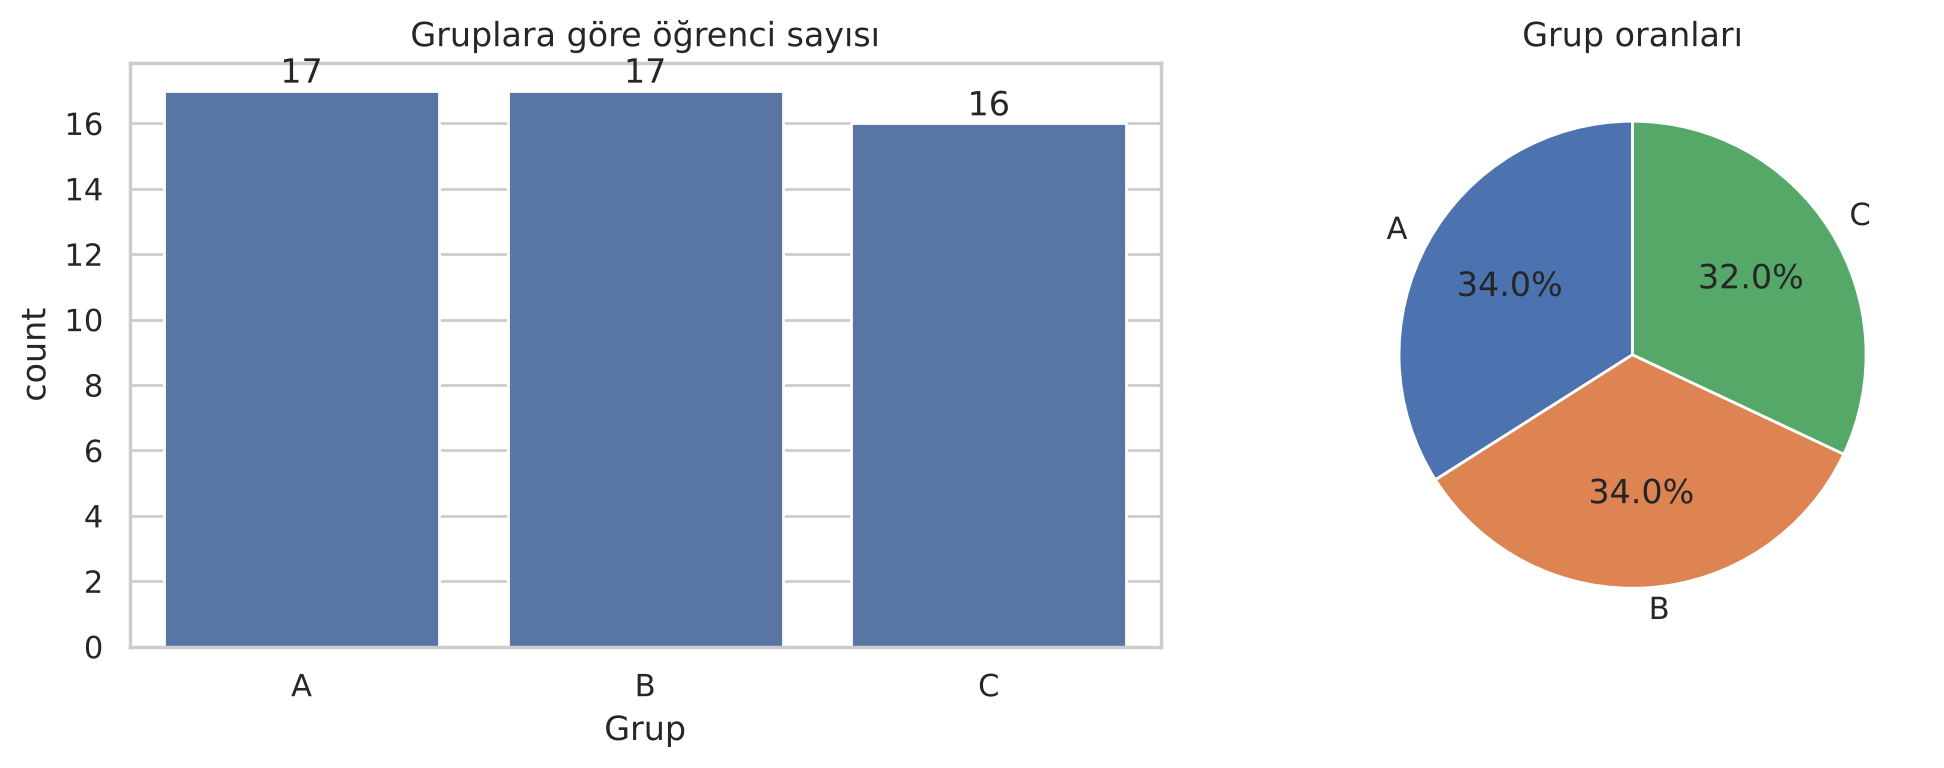

In [4]:
grup_dagilim = ogrenciler["Grup"].value_counts().sort_index()
print(grup_dagilim)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=ogrenciler, x="Grup", order=grup_dagilim.index, ax=ax[0])
ax[0].set_title("Gruplara göre öğrenci sayısı")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[1].pie(grup_dagilim, labels=grup_dagilim.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Grup oranları")
plt.tight_layout(); plt.show()

## 2. Normalizasyon
Min-Max normalizasyonu: $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ → değerler 0-1 aralığına çekilir, böylece 0-100'lük not ile 0-10'luk puan aynı ölçekte toplanabilir.

In [5]:
def min_max_normalize(seri: pd.Series) -> pd.Series:
    return (seri - seri.min()) / (seri.max() - seri.min())

df["Not_norm"] = min_max_normalize(df["Not"])
df["Puan_norm"] = min_max_normalize(df["Puan"])
df[["Not", "Not_norm", "Puan", "Puan_norm"]].describe().round(3)

,Not,Not_norm,Puan,Puan_norm
count,650.000,650.000,650.000,650.000
mean,73.212,0.732,4.302,0.478
std,39.873,0.399,2.629,0.292
min,0.000,0.000,0.000,0.000
25%,50.000,0.500,3.000,0.333
50%,100.000,1.000,5.000,0.556
75%,100.000,1.000,6.000,0.667
max,100.000,1.000,9.000,1.000


## 3. Başarı ölçüsü
`Basari = Not_norm * 0.7 + Puan_norm * 0.3`

In [6]:
df["Basari"] = df["Not_norm"] * 0.7 + df["Puan_norm"] * 0.3
df[["Tarih", "No", "Ad Soyad", "Grup", "Not_norm", "Puan_norm", "Basari"]].head()

,Tarih,No,Ad Soyad,Grup,Not_norm,Puan_norm,Basari
0,2022-10-10,1,Ahmet Yıldırım,A,0.5,0.333333,0.45
1,2022-10-10,2,Mehmet Demir,B,1.0,0.666667,0.90
2,2022-10-10,3,Ayşe Kaya,C,1.0,0.666667,0.90
3,2022-10-10,4,Fatma Şahin,A,1.0,0.666667,0.90
4,2022-10-10,5,Hasan Arslan,B,1.0,0.666667,0.90


## 4. En başarılı N öğrenci (tüm tarihler)

,No,Ad Soyad,Grup,Basari
1,4,Fatma Şahin,A,0.8949
2,3,Ayşe Kaya,C,0.8949
3,17,Barış Kurt,B,0.8949
4,37,Volkan Ersoy,A,0.8949
5,42,Levent Güney,C,0.8949
6,44,Metin Baştürk,B,0.8949
7,49,Doğan Güler,A,0.8949
8,40,Ahmetcan Karakaya,A,0.8949
9,27,Kadir Kılıç,C,0.8949
10,23,Cemal Sezer,B,0.8949


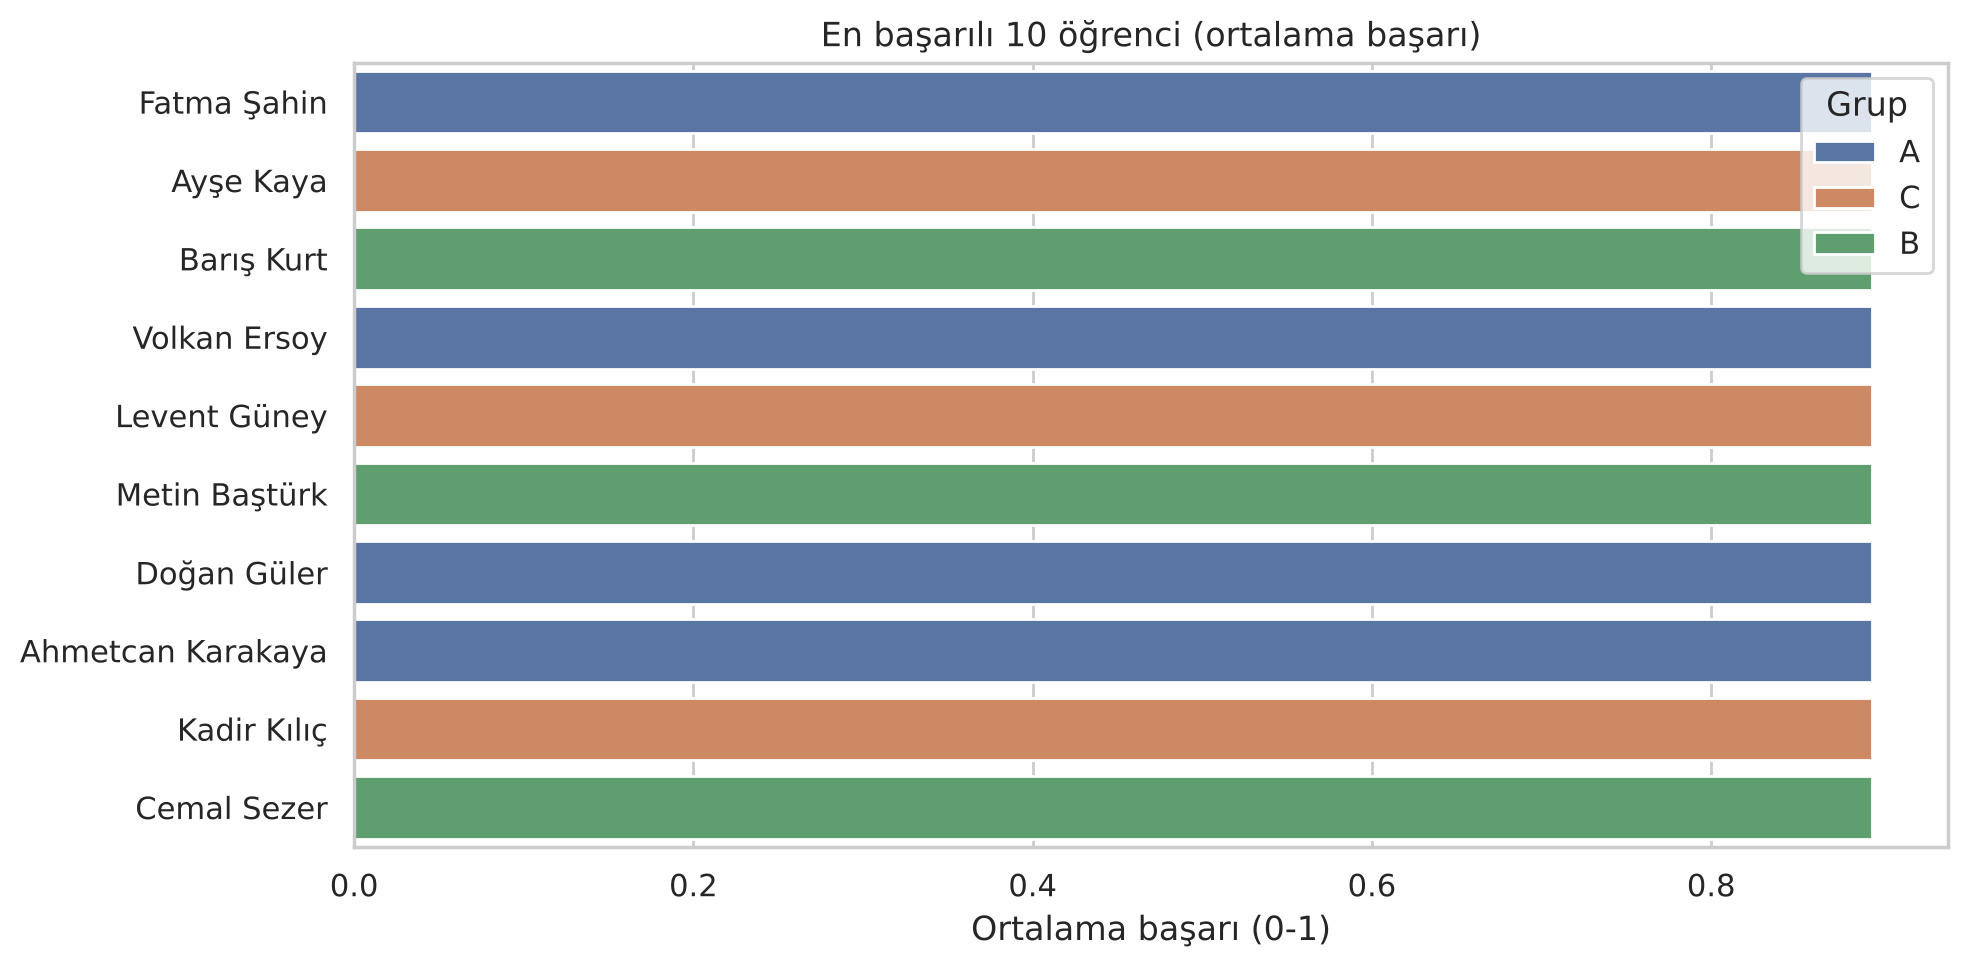

In [7]:
N = 10

ogrenci_basari = (df.groupby(["No", "Ad Soyad", "Grup"], as_index=False)["Basari"].mean()
                    .sort_values("Basari", ascending=False)
                    .reset_index(drop=True))
ogrenci_basari.index += 1
top_n = ogrenci_basari.head(N)
display(top_n.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(data=top_n, y="Ad Soyad", x="Basari", hue="Grup", dodge=False)
plt.title(f"En başarılı {N} öğrenci (ortalama başarı)")
plt.xlabel("Ortalama başarı (0-1)"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 5. En başarılı grup (tüm tarihler)

,mean,median,std
Grup,,,
B,0.6743,0.8667,0.3476
A,0.6541,0.8667,0.3584
C,0.6382,0.8333,0.3730


En başarılı grup: B


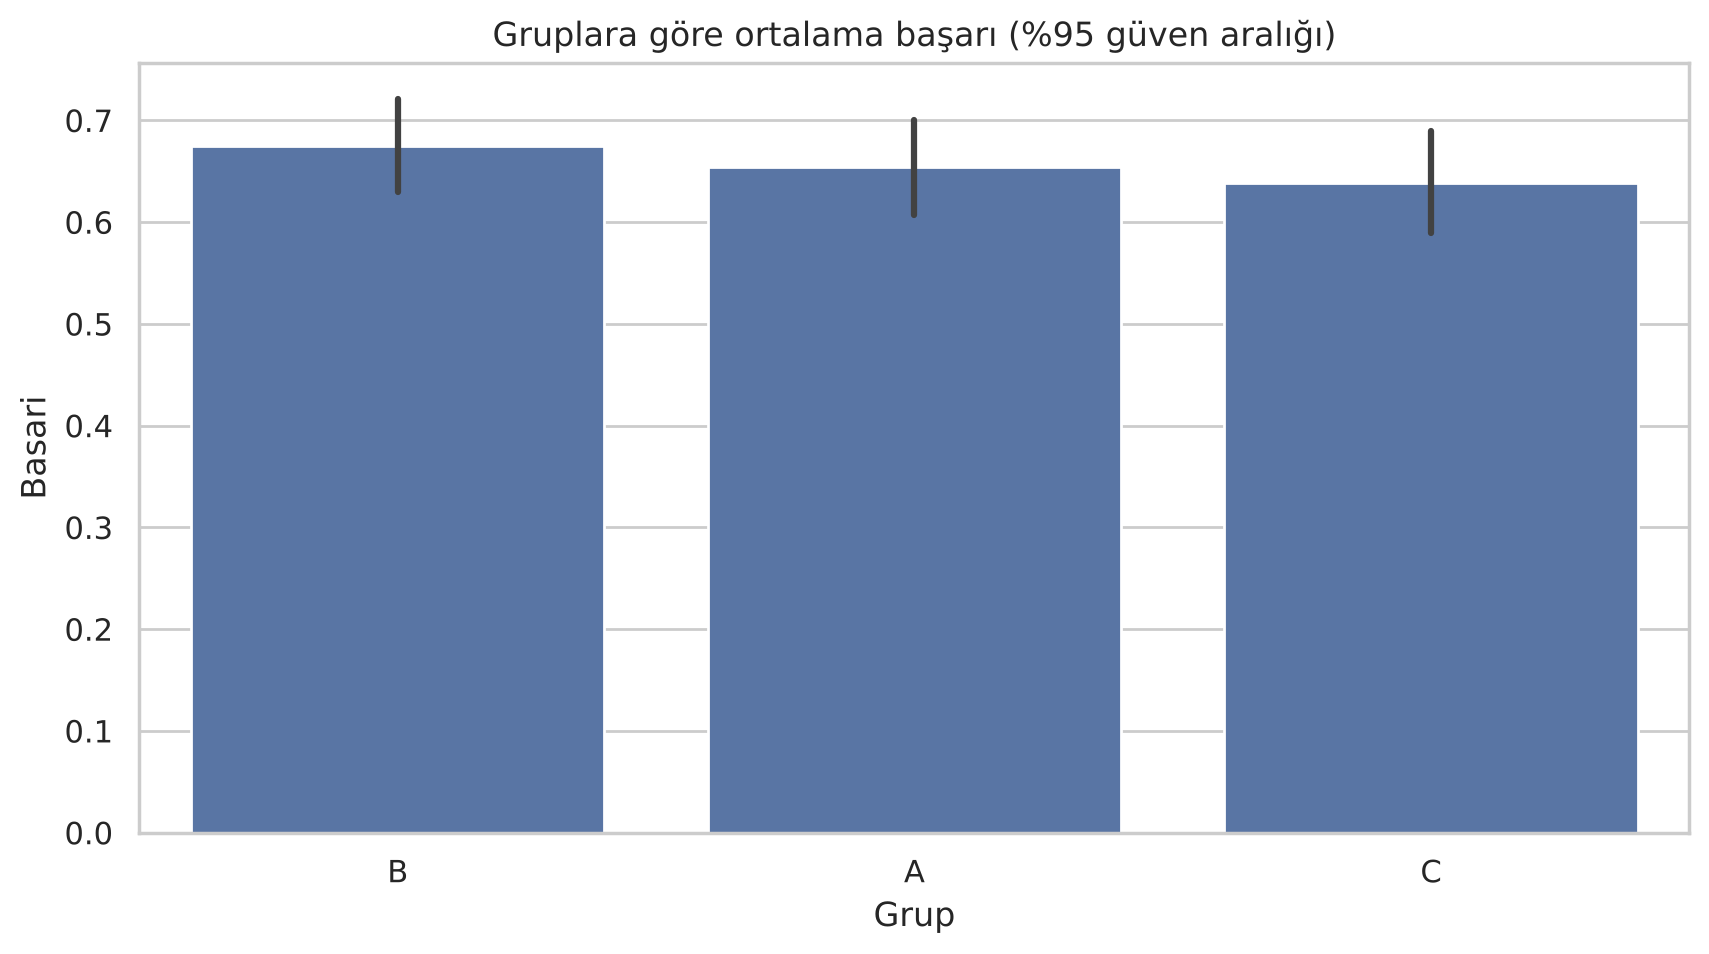

In [8]:
grup_basari = df.groupby("Grup")["Basari"].agg(["mean", "median", "std"]).sort_values("mean", ascending=False)
display(grup_basari.round(4))
print("En başarılı grup:", grup_basari.index[0])

ax = sns.barplot(data=df, x="Grup", y="Basari", order=grup_basari.index, errorbar="ci")
ax.set_title("Gruplara göre ortalama başarı (%95 güven aralığı)")
plt.show()

## 6. Grupların verilen tarih aralığında başarı grafiği

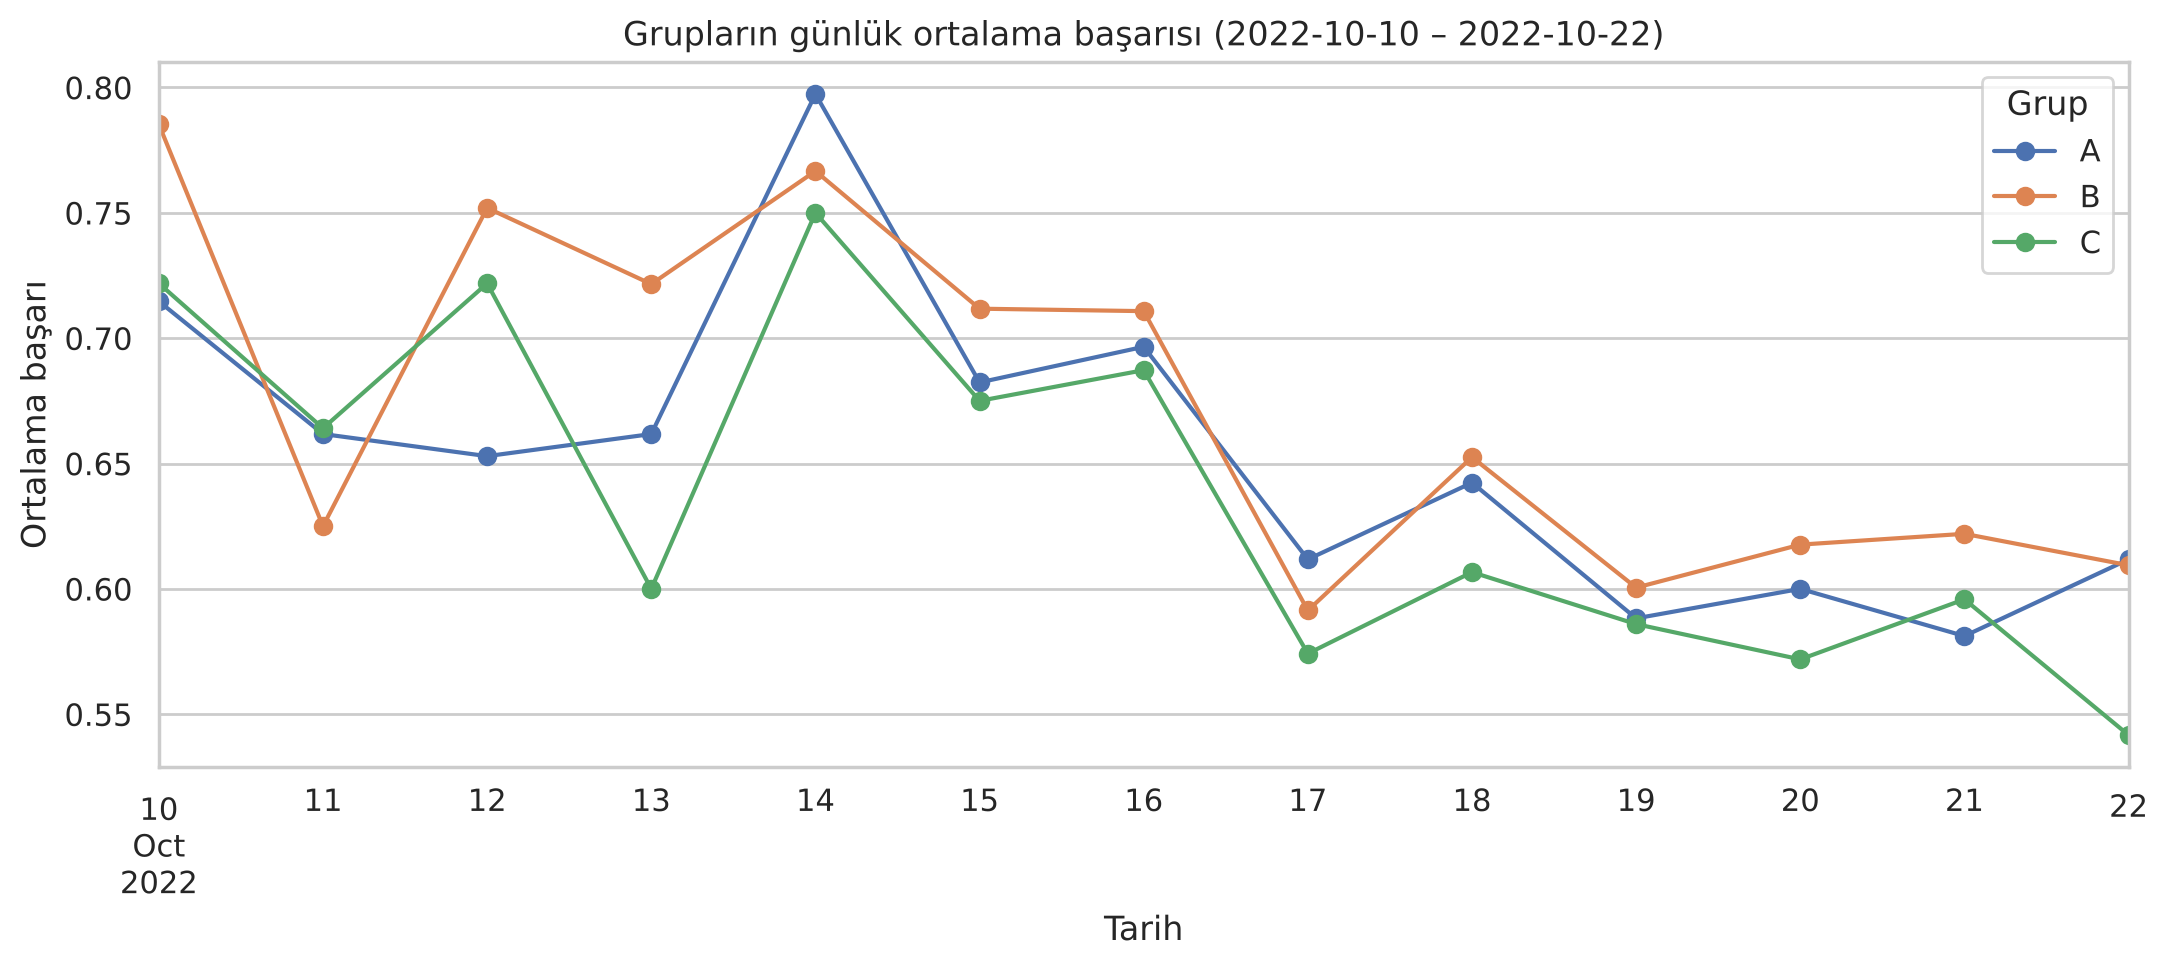

Grup,A,B,C
Tarih,,,
2022-10-10,0.715,0.785,0.722
2022-10-11,0.662,0.625,0.664
2022-10-12,0.653,0.752,0.722
2022-10-13,0.662,0.722,0.600
2022-10-14,0.797,0.767,0.750
2022-10-15,0.682,0.712,0.675
2022-10-16,0.697,0.711,0.687
2022-10-17,0.612,0.591,0.574
2022-10-18,0.642,0.653,0.607


In [9]:
def grup_basari_grafigi(veri, baslangic, bitis):
    aralik = veri[veri["Tarih"].between(pd.Timestamp(baslangic), pd.Timestamp(bitis))]
    gunluk = aralik.groupby(["Tarih", "Grup"])["Basari"].mean().unstack()
    ax = gunluk.plot(marker="o", figsize=(11, 5))
    ax.set_title(f"Grupların günlük ortalama başarısı ({baslangic} – {bitis})")
    ax.set_xlabel("Tarih"); ax.set_ylabel("Ortalama başarı")
    plt.tight_layout(); plt.show()
    return gunluk

# Tarih aralığını buradan değiştirebilirsiniz
grup_basari_grafigi(df, "2022-10-10", "2022-10-22").round(3)

## 7. Günlük sınav ortalamasının değişimi

,Ortalama,Degisim,Degisim_%
Tarih,,,
2022-10-10,82.33,NaN,NaN
2022-10-11,78.00,-4.33,-5.26
2022-10-12,78.67,0.67,0.85
2022-10-13,73.67,-5.00,-6.36
2022-10-14,77.11,3.44,4.68
2022-10-15,74.00,-3.11,-4.04
2022-10-16,72.25,-1.75,-2.36
2022-10-17,68.40,-3.85,-5.33
2022-10-18,73.20,4.80,7.02


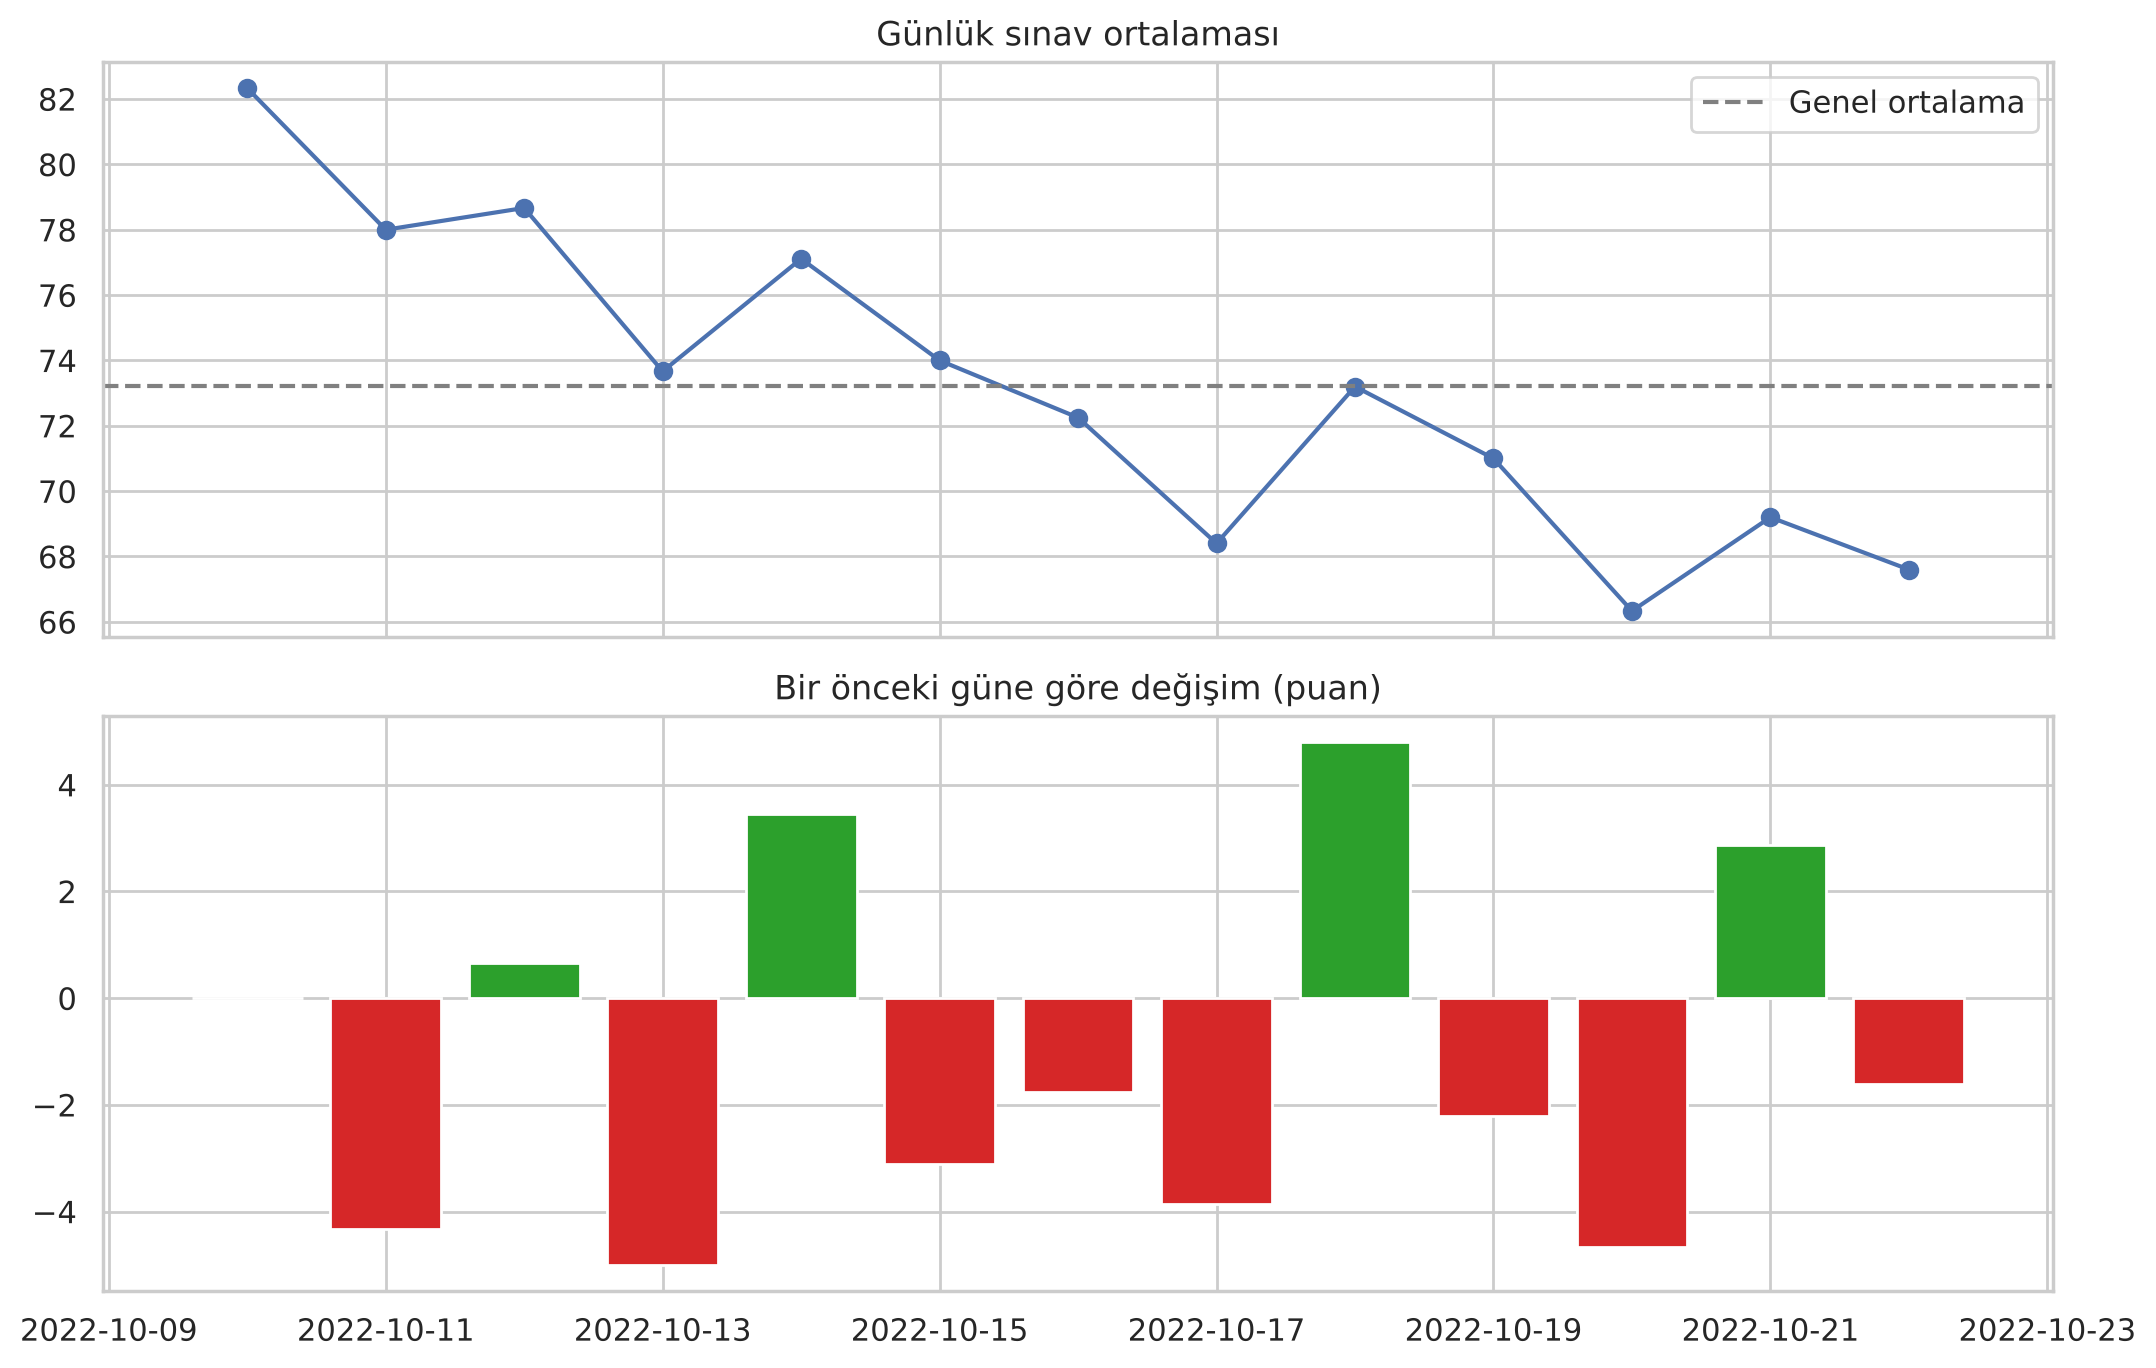

In [10]:
gunluk_sinav = df.groupby("Tarih")["Not"].mean().to_frame("Ortalama")
gunluk_sinav["Degisim"] = gunluk_sinav["Ortalama"].diff()
gunluk_sinav["Degisim_%"] = gunluk_sinav["Ortalama"].pct_change() * 100
display(gunluk_sinav.round(2))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(gunluk_sinav.index, gunluk_sinav["Ortalama"], marker="o")
ax[0].axhline(gunluk_sinav["Ortalama"].mean(), ls="--", c="gray", label="Genel ortalama")
ax[0].set_title("Günlük sınav ortalaması"); ax[0].legend()
renk = np.where(gunluk_sinav["Degisim"].fillna(0) >= 0, "tab:green", "tab:red")
ax[1].bar(gunluk_sinav.index, gunluk_sinav["Degisim"].fillna(0), color=renk)
ax[1].set_title("Bir önceki güne göre değişim (puan)")
plt.tight_layout(); plt.show()

## 8. Tanımlayıcı istatistikler (Ortalama, Medyan, Mod, Standart Sapma)

In [11]:
def tanimlayici(seri):
    return pd.Series({
        "Ortalama": seri.mean(),
        "Medyan": seri.median(),
        "Mod": seri.mode().iloc[0],
        "Std": seri.std(),
    })

# Genel
genel = pd.DataFrame({"Sınav Notu": tanimlayici(df["Not"]),
                      "Değerlendirme Puanı": tanimlayici(df["Puan"])})
display(genel.round(2))

# Grup bazında
grup_ist = df.groupby("Grup")[["Not", "Puan"]].agg(["mean", "median", lambda s: s.mode().iloc[0], "std"])
grup_ist = grup_ist.rename(columns={"mean": "Ortalama", "median": "Medyan", "<lambda_0>": "Mod", "std": "Std"})
display(grup_ist.round(2))

# Öğrenci bazında
ogr_ist = df.groupby(["No", "Ad Soyad"])[["Not", "Puan"]].agg(["mean", "median", "std"]).round(2)
display(ogr_ist.head(10))

,Sınav Notu,Değerlendirme Puanı
Ortalama,73.21,4.30
Medyan,100.00,5.00
Mod,100.00,5.00
Std,39.87,2.63


Not                          Puan                 
     Ortalama Medyan    Mod    Std Ortalama Medyan Mod   Std
Grup                                                        
A       73.03  100.0  100.0  39.69     4.29    5.0   5  2.64
B       75.22  100.0  100.0  38.70     4.43    5.0   6  2.54
C       71.27  100.0  100.0  41.36     4.18    5.0   0  2.71

Not                 Puan             
                     mean  median    std  mean median   std
No Ad Soyad                                                
1  Ahmet Yıldırım   67.67   66.67  24.89  4.00    4.0  1.87
2  Mehmet Demir     97.18  100.00   6.92  5.69    5.0  1.55
3  Ayşe Kaya       100.00  100.00   0.00  5.85    6.0  1.46
4  Fatma Şahin     100.00  100.00   0.00  5.85    6.0  1.46
5  Hasan Arslan     71.26  100.00  41.94  4.23    5.0  2.77
6  Hüseyin Yalçın   91.67  100.00  23.57  5.38    5.0  2.06
7  Zeynep Aydın     95.64  100.00  11.66  5.62    5.0  1.66
8  Emre Korkmaz     88.46  100.00  16.39  5.15    5.0  1.52
9  Elif Çetin        6.41    0.00  23.11  0.38    0.0  1.39
10 Murat Koç         1.28    0.00   4.62  0.08    0.0  0.28

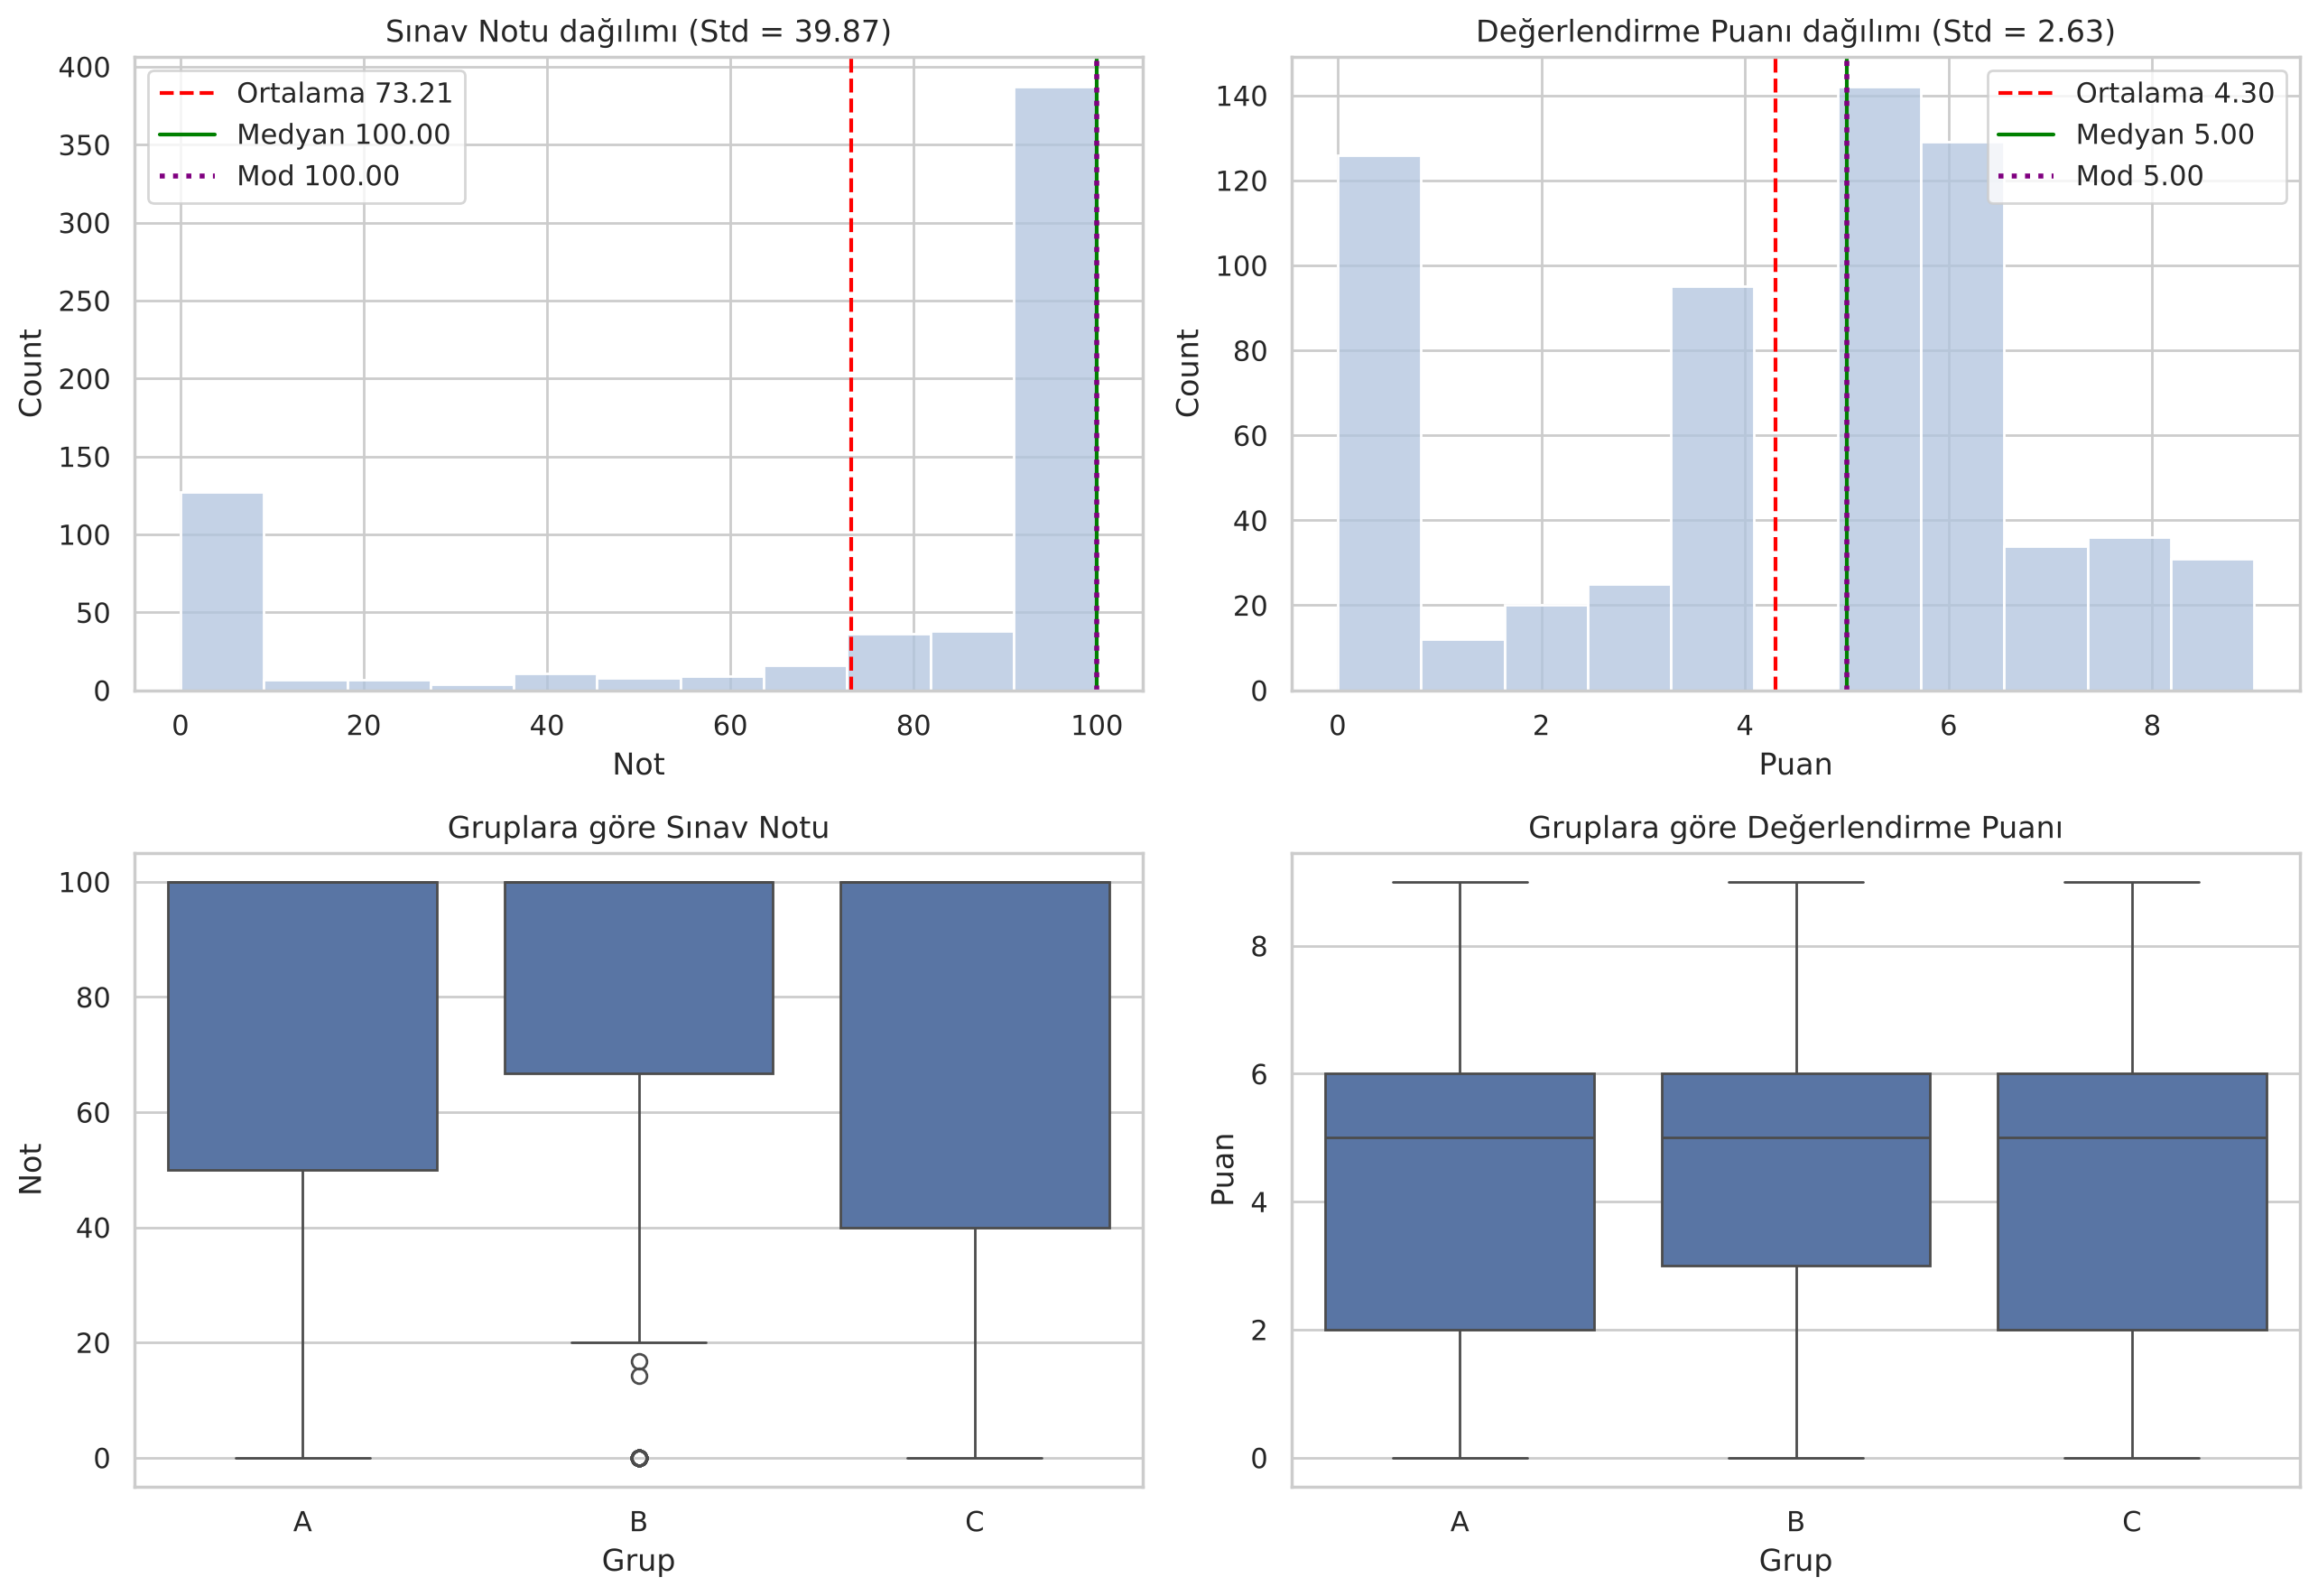

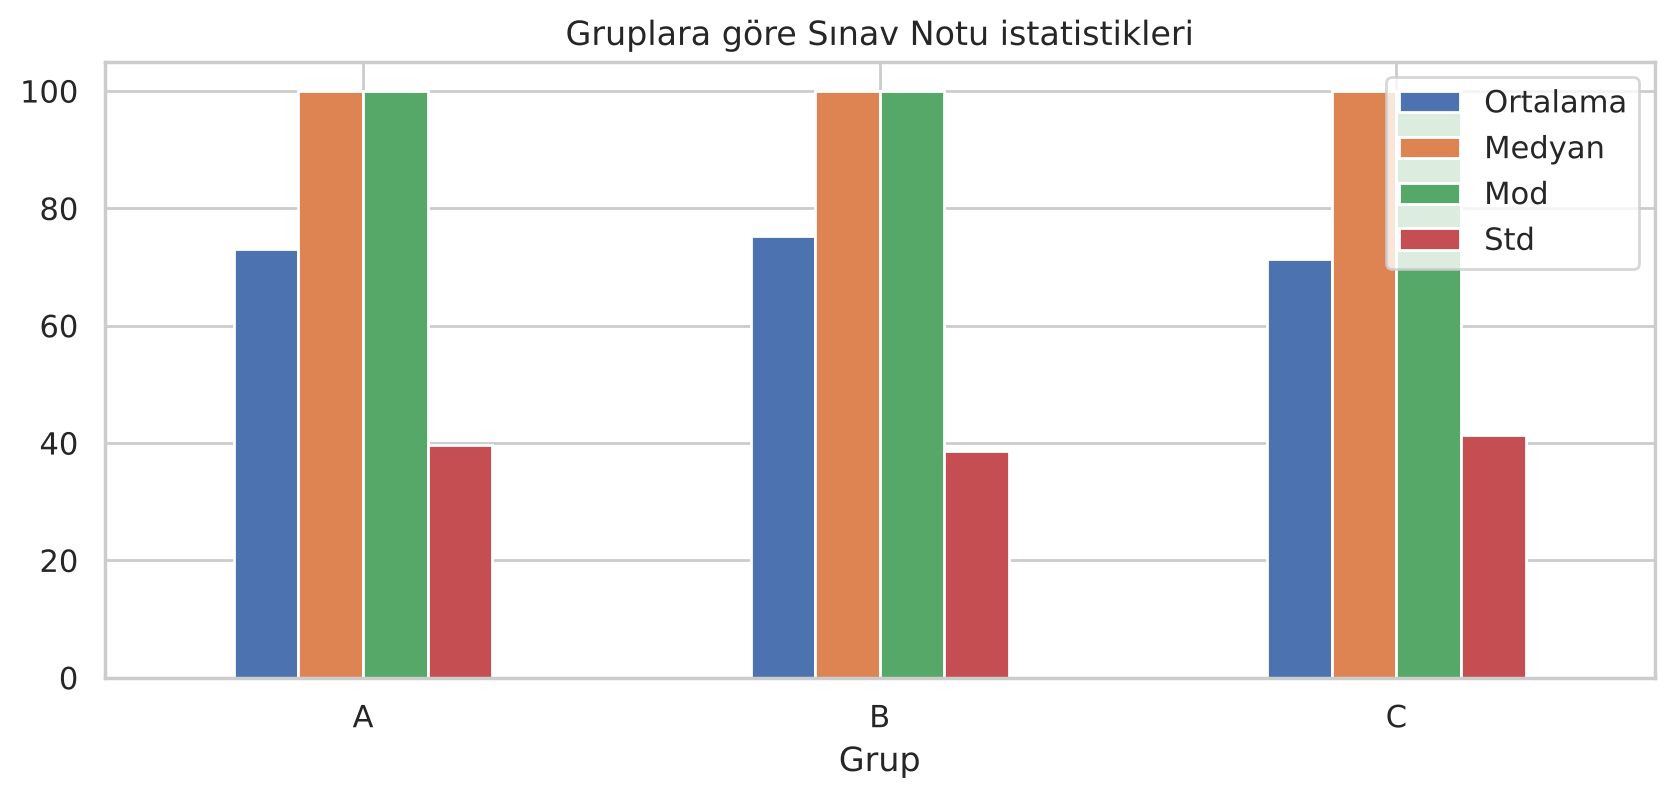

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for i, (kolon, baslik) in enumerate([("Not", "Sınav Notu"), ("Puan", "Değerlendirme Puanı")]):
    ist = tanimlayici(df[kolon])
    sns.histplot(df[kolon], bins=11, ax=ax[0, i], color="lightsteelblue")
    ax[0, i].axvline(ist["Ortalama"], c="red", ls="--", label=f"Ortalama {ist['Ortalama']:.2f}")
    ax[0, i].axvline(ist["Medyan"], c="green", ls="-", label=f"Medyan {ist['Medyan']:.2f}")
    ax[0, i].axvline(ist["Mod"], c="purple", ls=":", lw=2, label=f"Mod {ist['Mod']:.2f}")
    ax[0, i].set_title(f"{baslik} dağılımı (Std = {ist['Std']:.2f})"); ax[0, i].legend()
    sns.boxplot(data=df, x="Grup", y=kolon, order=["A", "B", "C"], ax=ax[1, i])
    ax[1, i].set_title(f"Gruplara göre {baslik}")
plt.tight_layout(); plt.show()

# Grup bazında istatistiklerin karşılaştırılması
grup_ist.xs("Not", axis=1, level=0).plot(kind="bar", figsize=(10, 4), title="Gruplara göre Sınav Notu istatistikleri", rot=0)
plt.show()

## 9. Soru: Sınav notu ile günlük değerlendirme puanı arasında ilişki var mı?
Eğitmenin verdiği günlük performans puanı, sınav başarısıyla ne kadar uyumlu?

Pearson korelasyonu : 0.890
Spearman korelasyonu: 0.784


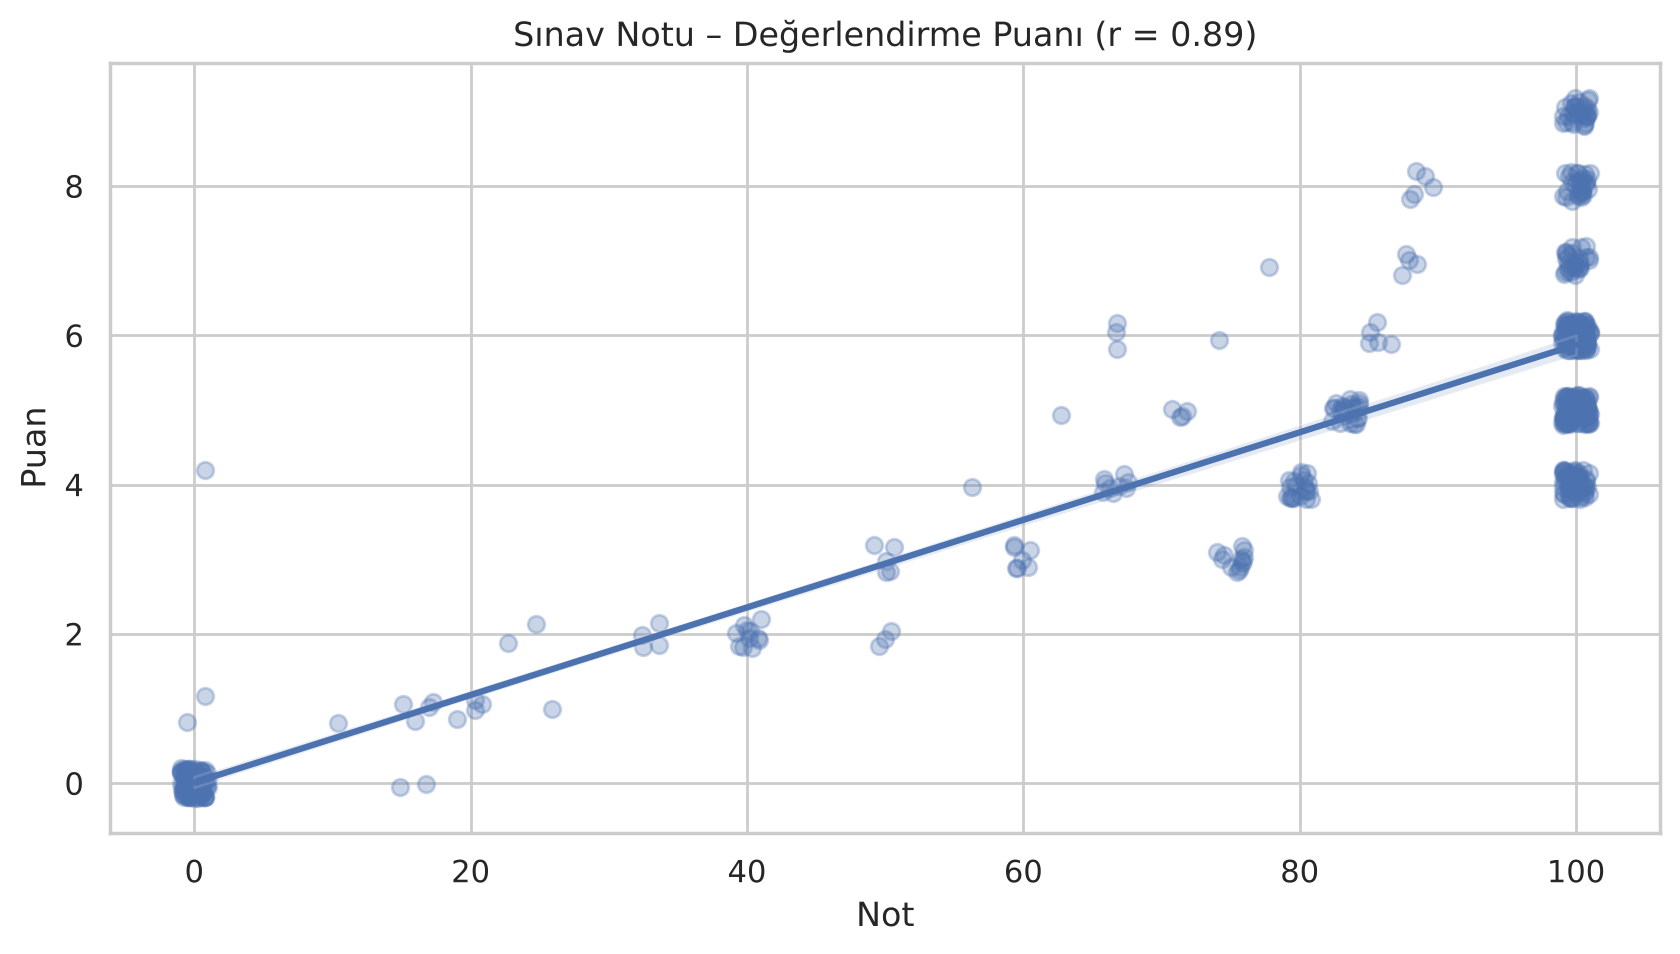

In [13]:
pearson = df["Not"].corr(df["Puan"], method="pearson")
spearman = df["Not"].corr(df["Puan"], method="spearman")
print(f"Pearson korelasyonu : {pearson:.3f}")
print(f"Spearman korelasyonu: {spearman:.3f}")

sns.regplot(data=df, x="Not", y="Puan", scatter_kws={"alpha": 0.3}, x_jitter=1, y_jitter=0.2)
plt.title(f"Sınav Notu – Değerlendirme Puanı (r = {pearson:.2f})")
plt.show()

**Yorum:** Korelasyon katsayısı 1'e ne kadar yakınsa, değerlendirme puanı sınav notuyla o kadar uyumludur. Çok yüksek bir korelasyon, iki ölçünün büyük ölçüde aynı bilgiyi taşıdığını, dolayısıyla başarı formülündeki %30'luk değerlendirme payının sıralamayı çok az değiştirdiğini gösterir.

## 10. Soru: Dönem içinde en çok gelişen / en çok geriye giden öğrenciler kimler?
İlk 3 günün ortalama başarısı ile son 3 günün ortalama başarısı karşılaştırıldı.

En çok gelişen 5 öğrenci:


,No,Ad Soyad,Grup,Ilk_3_gun,Son_3_gun,Fark
0,32,Burak Demirtaş,B,0.000,0.878,0.878
1,46,Erdal Öztürk,A,0.000,0.820,0.820
2,1,Ahmet Yıldırım,A,0.458,0.720,0.262
3,5,Hasan Arslan,B,0.600,0.820,0.220
4,45,Serhat Yılmaz,C,0.828,0.878,0.050


En çok geriye giden 5 öğrenci:


,No,Ad Soyad,Grup,Ilk_3_gun,Son_3_gun,Fark
45,15,Mustafa Erdem,C,0.678,0.0,-0.678
46,16,Cengiz Özkan,A,0.708,0.0,-0.708
47,25,İsmail Şen,A,0.778,0.0,-0.778
48,47,Şahin Tekin,B,0.808,0.0,-0.808
49,26,Mahir Karaca,B,0.878,0.0,-0.878


Gruplara göre ortalama gelişim:


Grup
A   -0.079
B   -0.104
C   -0.133
Name: Fark, dtype: float64

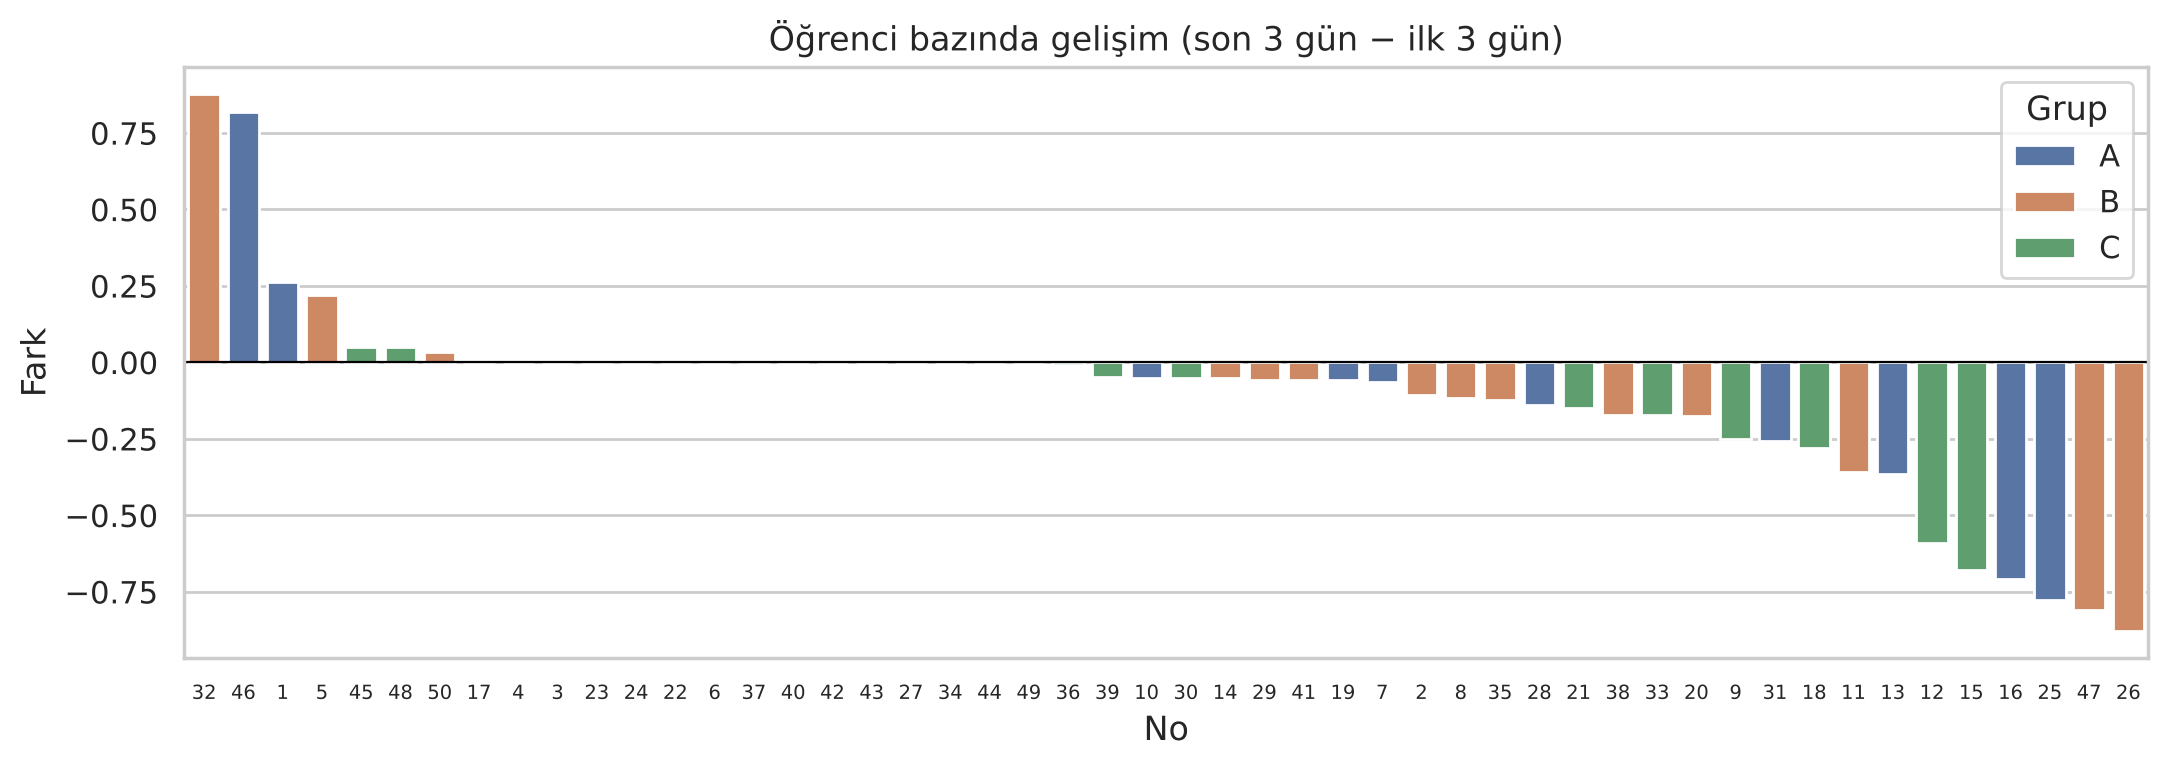

In [14]:
tarihler = sorted(df["Tarih"].unique())
ilk = df[df["Tarih"].isin(tarihler[:3])].groupby(["No", "Ad Soyad", "Grup"])["Basari"].mean()
son = df[df["Tarih"].isin(tarihler[-3:])].groupby(["No", "Ad Soyad", "Grup"])["Basari"].mean()
gelisim = pd.DataFrame({"Ilk_3_gun": ilk, "Son_3_gun": son})
gelisim["Fark"] = gelisim["Son_3_gun"] - gelisim["Ilk_3_gun"]
gelisim = gelisim.sort_values("Fark", ascending=False).reset_index()

print("En çok gelişen 5 öğrenci:")
display(gelisim.head(5).round(3))
print("En çok geriye giden 5 öğrenci:")
display(gelisim.tail(5).round(3))
print("Gruplara göre ortalama gelişim:")
display(gelisim.groupby("Grup")["Fark"].mean().round(3))

plt.figure(figsize=(11, 4))
sns.barplot(data=gelisim, x="No", y="Fark", hue="Grup", dodge=False, order=gelisim["No"])
plt.axhline(0, c="black", lw=0.8)
plt.title("Öğrenci bazında gelişim (son 3 gün − ilk 3 gün)")
plt.xticks(fontsize=7); plt.tight_layout(); plt.show()

## Sonuç
Yukarıdaki çıktılar; grup dağılımını, normalize edilmiş başarı ölçüsünü, en başarılı öğrenci ve grupları, zaman içindeki değişimi, tanımlayıcı istatistikleri ve iki ek analiz sorusunu (not–puan ilişkisi, öğrenci gelişimi) içermektedir.